<a href="https://colab.research.google.com/github/rajalakshmie-png/confidentiality-gate/blob/main/LAF_MCDM_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAF-MCDM: fuzzy AHP–TOPSIS pipeline for cyber-risk prioritization
Human-in-the-loop, LLM-compatible proof-of-concept. Every "LLM" role is a deterministic rule.

In [ ]:
import platform, json, numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
import lafmcdm as L
pd.set_option("display.precision", 3)
print("Python    ", platform.python_version())
print("NumPy     ", np.__version__)
print("pandas    ", pd.__version__)
print("Matplotlib", matplotlib.__version__)
!ls data

Python     3.13.18
NumPy      2.5.3
pandas     3.0.5
Matplotlib 3.11.2
credibility_matrix.json  expert_weights_table9.json
expert_matrices.json	 ratings_table7.json


## Module 1 · Semantic elicitation
Rationale text → candidate TFN, returned to the expert for confirmation.

In [ ]:
rationales = {
    ("C2 Impact", "C1 Likelihood"): "Impact is clearly more important than likelihood for board reporting",
    ("C5 Regulatory", "C4 Remediation cost"): "Regulatory exposure overwhelmingly dominates cost for us",
    ("C1 Likelihood", "C3 Detectability"): "Likelihood is slightly more relevant than detectability",
    ("C3 Detectability", "C4 Remediation cost"): "Both matter about equal",
}
rows = []
for (a, b), text in rationales.items():
    value, label, t = L.elicit(text)
    rows.append([f"{a} vs {b}", text, label, value, tuple(t.astype(int))])
pd.DataFrame(rows, columns=["Pair", "Expert rationale", "Class", "Saaty", "Candidate TFN"])

,Pair,Expert rationale,Class,Saaty,Candidate TFN
0,C2 Impact vs C1 Likelihood,Impact is clearly more important than likeliho...,Strong,5,"(4, 5, 6)"
1,C5 Regulatory vs C4 Remediation cost,Regulatory exposure overwhelmingly dominates c...,Extreme,9,"(9, 9, 9)"
2,C1 Likelihood vs C3 Detectability,Likelihood is slightly more relevant than dete...,Moderate,3,"(2, 3, 4)"
3,C3 Detectability vs C4 Remediation cost,Both matter about equal,Equal,1,"(1, 1, 1)"


## Module 2 · Consistency refinement
Median-transitivity repair of CR-violating matrices.

In [ ]:
mats = {k: np.array(v) for k, v in json.load(open("data/expert_matrices.json"))["matrices"].items()}
rows, logs = [], {}
for name, A in mats.items():
    cr0 = L.consistency_ratio(A)
    A2, log = L.refine(A)
    logs[name] = log
    rows.append([name, cr0, L.consistency_ratio(A2) if log else None, len(log)])
pd.DataFrame(rows, columns=["Expert", "CR before", "CR after", "Iterations"])

,Expert,CR before,CR after,Iterations
0,CISO,0.004,NaN,0
1,SOC analyst,0.004,NaN,0
2,Compliance officer,0.115,0.002,1
3,IT infra lead,0.122,0.003,1
4,Ext. consultant,0.013,NaN,0


In [ ]:
for name, log in logs.items():
    for s in log:
        print(f"{name:20s} iter {s['iteration']}: a{s['entry']} {s['old']:.3f} -> {s['new']:.3f}"
              f"   CR {s['cr_before']:.3f} -> {s['cr_after']:.3f}   [awaiting expert confirmation]")

Compliance officer   iter 1: a(1, 3) 0.250 -> 1.750   CR 0.115 -> 0.002   [awaiting expert confirmation]
IT infra lead        iter 1: a(1, 3) 9.000 -> 1.250   CR 0.122 -> 0.003   [awaiting expert confirmation]


## Module 3 · Group aggregation
Per-expert weights (paper, Table IX) combined by geometric mean vs role credibility.

In [ ]:
W = np.array(list(json.load(open("data/expert_weights_table9.json"))["weights"].values()))
Cred = np.array(json.load(open("data/credibility_matrix.json"))["criteria_x_experts"])
w_gm, w_rw = L.geomean_aggregate(W), L.role_aggregate(W, Cred)
pd.DataFrame({"GeoMean": w_gm, "Role-weighted": w_rw,
              "Expert min": W.min(0), "Expert max": W.max(0)}, index=L.CRITERIA)

,GeoMean,Role-weighted,Expert min,Expert max
C1 Likelihood,0.208,0.154,0.119,0.264
C2 Impact,0.355,0.257,0.220,0.416
C3 Detectability,0.136,0.165,0.068,0.390
C4 Remediation cost,0.139,0.201,0.056,0.495
C5 Regulatory,0.161,0.223,0.046,0.504


## Fuzzy TOPSIS ranking

In [ ]:
ratings = json.load(open("data/ratings_table7.json"))["ratings"]
res = {}
for label, w in [("GeoMean", w_gm), ("Role-weighted", w_rw), ("Equal", np.full(5, 0.2))]:
    res[label] = L.fuzzy_topsis(ratings, w)[2]
table = pd.DataFrame(res, index=L.ALTS).sort_values("GeoMean", ascending=False)
table.insert(0, "Rank", range(1, 7))
table

,Rank,GeoMean,Role-weighted,Equal
R1 Ransomware,1,0.736,0.704,0.681
R5 Supply-chain,2,0.681,0.694,0.664
R4 Cloud misconfig.,3,0.618,0.616,0.594
R2 Insider threat,4,0.594,0.584,0.564
R3 Phishing,5,0.491,0.446,0.449
R6 DDoS,6,0.422,0.372,0.372


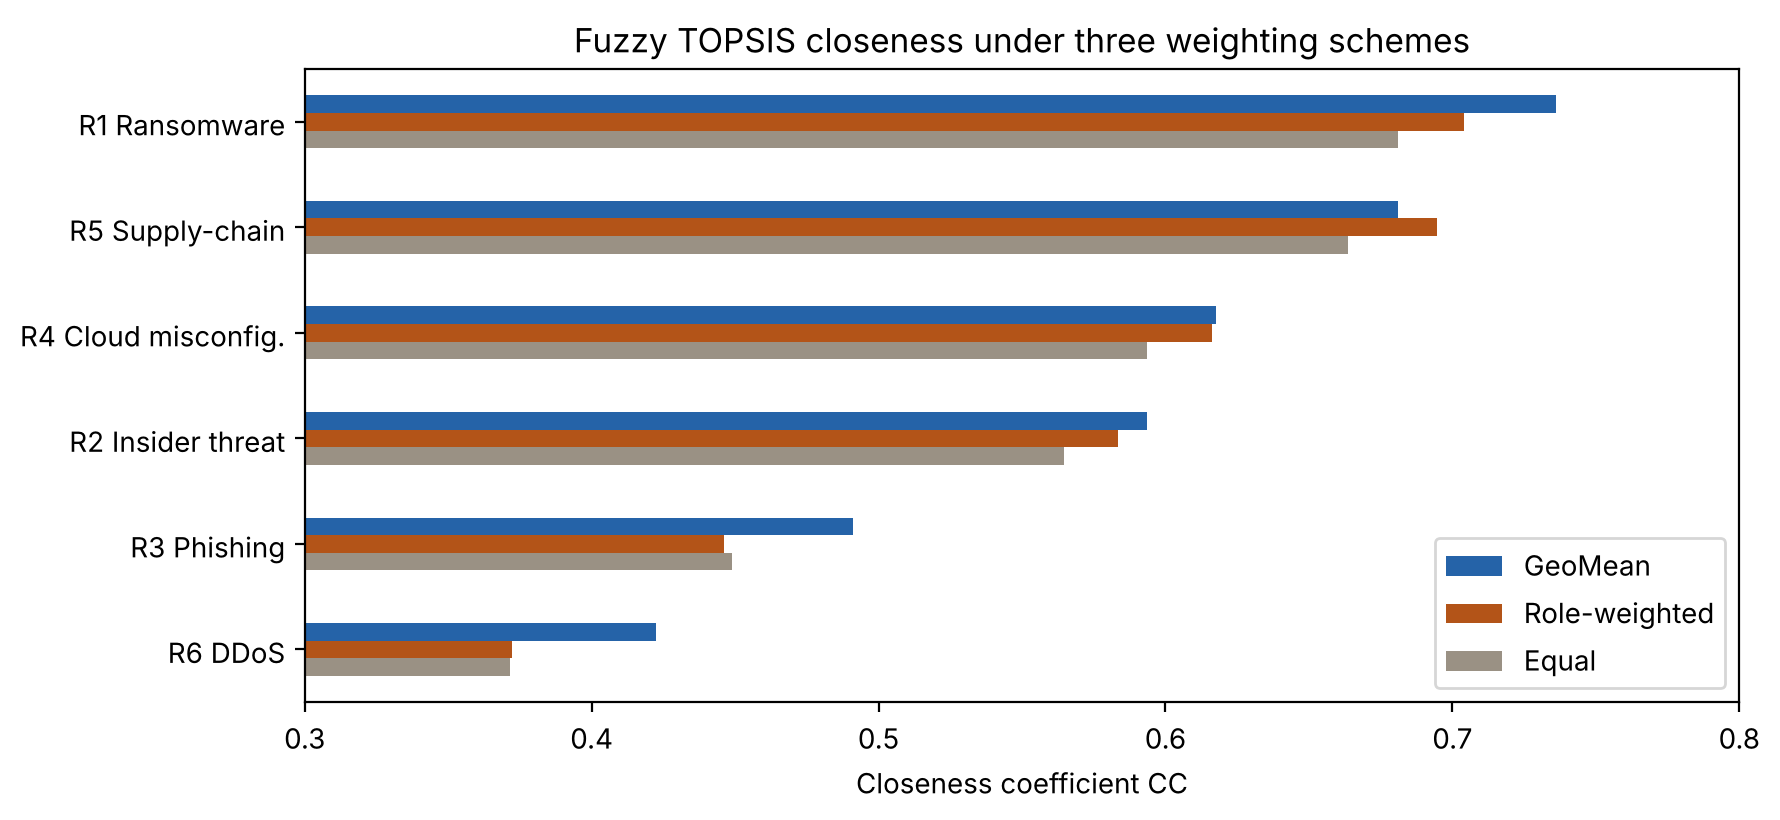

In [ ]:
ax = table.drop(columns="Rank").plot.barh(figsize=(9, 4.2), color=["#2563A8", "#B35418", "#9A9184"])
ax.invert_yaxis(); ax.set_xlabel("Closeness coefficient CC"); ax.set_xlim(0.3, 0.8)
ax.set_title("Fuzzy TOPSIS closeness under three weighting schemes"); plt.tight_layout()
plt.savefig("figures/topsis_cc.png", dpi=150)

## Monte Carlo robustness · 10,000 Dirichlet draws (α = 40)

In [ ]:
%%time
mc = {}
for label, w in [("GeoMean", w_gm), ("Role-weighted", w_rw)]:
    top, _ = L.monte_carlo(ratings, w, runs=10_000, alpha=40, seed=42)
    mc[label] = np.bincount(top, minlength=6) / len(top) * 100
pd.DataFrame(mc, index=L.ALTS).round(2).rename(columns=lambda c: c + " P(rank 1) %")

CPU times: user 796 ms, sys: 3.26 ms, total: 800 ms
Wall time: 805 ms


,GeoMean P(rank 1) %,Role-weighted P(rank 1) %
R1 Ransomware,87.37,57.87
R2 Insider threat,0.00,0.00
R3 Phishing,0.00,0.00
R4 Cloud misconfig.,0.00,0.01
R5 Supply-chain,12.63,42.12
R6 DDoS,0.00,0.00


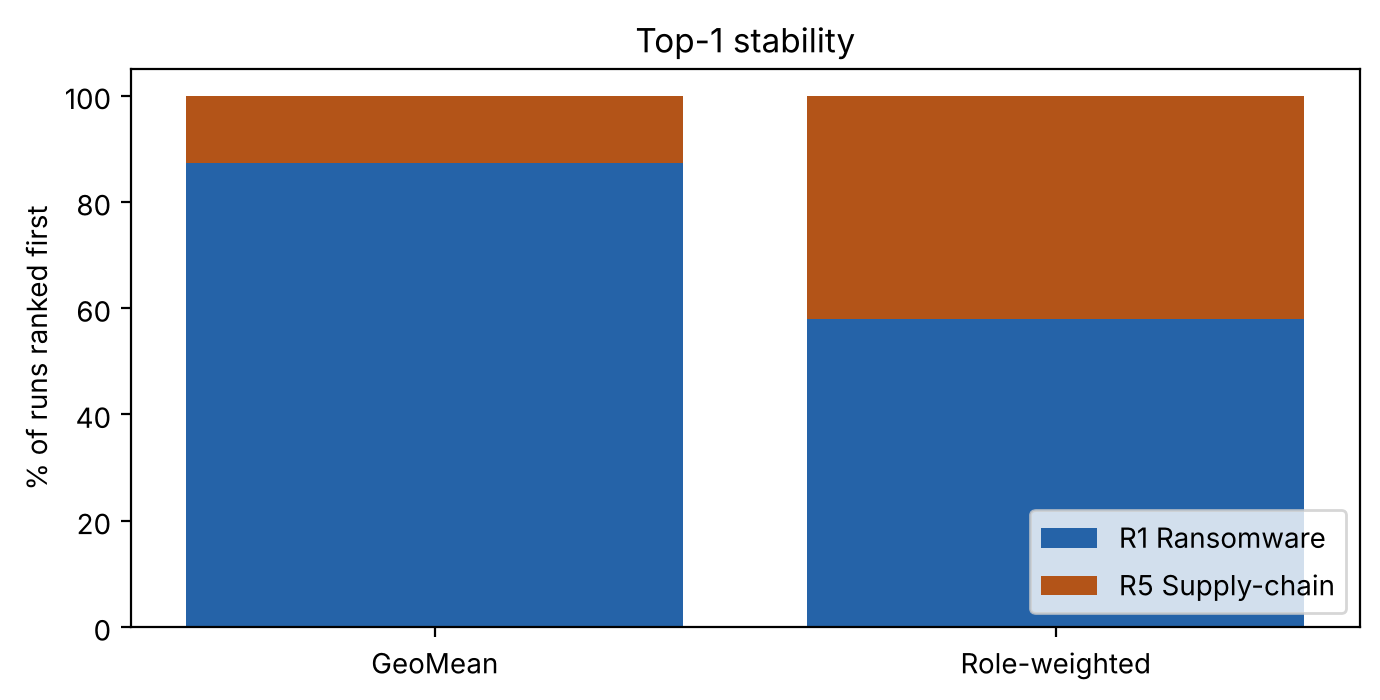

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(["GeoMean", "Role-weighted"], [mc["GeoMean"][0], mc["Role-weighted"][0]], color="#2563A8", label="R1 Ransomware")
ax.bar(["GeoMean", "Role-weighted"], [mc["GeoMean"][4], mc["Role-weighted"][4]],
       bottom=[mc["GeoMean"][0], mc["Role-weighted"][0]], color="#B35418", label="R5 Supply-chain")
ax.set_ylabel("% of runs ranked first"); ax.legend(loc="lower right"); ax.set_title("Top-1 stability")
plt.tight_layout(); plt.savefig("figures/mc_top1.png", dpi=150)